# DATA ANALYTICS ML CHALLENGE / 2026-2
## Laboratorio 1. Modelos supervisados y métricas (Semana 12)

Profesor: Elias Buitrago Bolivar  
Universidad Central  
Caso: Brazilian E-Commerce Public Dataset by Olist

Objetivo: construir un modelo base para anticipar entregas tardías a partir de datos de compras, productos, clientes, vendedores y pagos.

Las instrucciones de GitHub y entrega se encuentran en el documento técnico. Las secciones de carga y preparación se suministran resueltas; complete las cuatro actividades de modelado y evaluación.

## 1. Carga de datos

Una observación del modelo corresponde a un pedido, aunque tenga varios productos y pagos. Se integrarán siete tablas del conjunto público de Olist.

In [1]:
import hashlib
import json
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score,
                             confusion_matrix, mean_absolute_error)

In [2]:
ORIGEN = ('https://raw.githubusercontent.com/spdrio/'
          'Brazilian-E-Commerce-Public-Dataset-by-Olist/'
          'fa0cc6d1aff713d3c8b9a1e633b56889881848bf/files')

pedidos = pd.read_csv(f'{ORIGEN}/olist_orders_dataset.csv')
items = pd.read_csv(f'{ORIGEN}/olist_order_items_dataset.csv')
productos = pd.read_csv(f'{ORIGEN}/olist_products_dataset.csv')
clientes = pd.read_csv(f'{ORIGEN}/olist_customers_dataset.csv')
vendedores = pd.read_csv(f'{ORIGEN}/olist_sellers_dataset.csv')
pagos = pd.read_csv(f'{ORIGEN}/olist_order_payments_dataset.csv')
categorias = pd.read_csv(f'{ORIGEN}/product_category_name_translation.csv')

print('Pedidos:', pedidos.shape)
print('Items:', items.shape)
print('Productos:', productos.shape)
print('Clientes:', clientes.shape)
print('Vendedores:', vendedores.shape)
print('Pagos:', pagos.shape)

Pedidos: (99441, 8)
Items: (112650, 7)
Productos: (32951, 9)
Clientes: (99441, 5)
Vendedores: (3095, 4)
Pagos: (103886, 5)


## 2. Preparación de variables

Un pedido puede contener varios ítems y pagos. Primero se resumen estas tablas por `order_id`, para evitar contar un mismo pedido varias veces. Las variables de destino se construyen después y no se incluyen entre los predictores.

In [3]:
# Información de los productos y vendedores incluidos en cada pedido.
items = items.merge(productos, on='product_id', how='left', validate='many_to_one')
items = items.merge(vendedores, on='seller_id', how='left', validate='many_to_one')
items = items.merge(categorias, on='product_category_name',
                    how='left', validate='many_to_one')

items['volumen_cm3'] = (items['product_length_cm'] * items['product_height_cm']
                       * items['product_width_cm'])
items['categoria'] = items['product_category_name_english'].fillna(
    items['product_category_name']).fillna('sin_categoria')

# Resumen de productos: una fila por pedido.
resumen_items = items.groupby('order_id', as_index=False).agg(
    valor_productos=('price', 'sum'),
    valor_flete=('freight_value', 'sum'),
    precio_maximo=('price', 'max'),
    cantidad_items=('order_item_id', 'count'),
    cantidad_productos=('product_id', 'nunique'),
    cantidad_vendedores=('seller_id', 'nunique'),
    peso_total_g=('product_weight_g', 'sum'),
    peso_maximo_g=('product_weight_g', 'max'),
    volumen_total_cm3=('volumen_cm3', 'sum'),
    fotos_promedio=('product_photos_qty', 'mean'),
    descripcion_promedio=('product_description_lenght', 'mean'),
    nombre_promedio=('product_name_lenght', 'mean'),
)

# Categoría y vendedor del producto de mayor precio del pedido.
principal = (items.sort_values(['order_id', 'price', 'order_item_id'],
                                ascending=[True, False, True])
             .drop_duplicates('order_id'))
principal = principal[['order_id', 'categoria', 'seller_state', 'seller_city']]
principal = principal.rename(columns={
    'categoria': 'categoria_principal',
    'seller_state': 'estado_vendedor',
    'seller_city': 'ciudad_vendedor'
})

In [4]:
# Los pagos también pueden aparecer en varias filas por pedido.
resumen_pagos = pagos.groupby('order_id', as_index=False).agg(
    numero_pagos=('payment_sequential', 'count'),
    cuotas_maximas=('payment_installments', 'max'),
    valor_pagado=('payment_value', 'sum'),
)

pago_principal = (pagos.sort_values(['order_id', 'payment_value'],
                                    ascending=[True, False])
                  .drop_duplicates('order_id'))
pago_principal = pago_principal[['order_id', 'payment_type']].rename(
    columns={'payment_type': 'tipo_pago_principal'})

# Integración de las tablas: una fila por pedido.
data = pedidos.merge(clientes[['customer_id', 'customer_state', 'customer_city']],
                     on='customer_id', how='inner', validate='one_to_one')
data = data.merge(resumen_items, on='order_id', how='inner', validate='one_to_one')
data = data.merge(principal, on='order_id', how='left', validate='one_to_one')
data = data.merge(resumen_pagos, on='order_id', how='left', validate='one_to_one')
data = data.merge(pago_principal, on='order_id', how='left', validate='one_to_one')

assert data['order_id'].is_unique, 'Hay pedidos duplicados después de las uniones.'
print('Pedidos integrados:', len(data))

Pedidos integrados: 98666


In [5]:
# Se consideran pedidos entregados con fechas completas y coherentes.
fechas = ['order_purchase_timestamp', 'order_estimated_delivery_date',
          'order_delivered_customer_date']
for columna in fechas:
    data[columna] = pd.to_datetime(data[columna], errors='coerce')

data = data.loc[data['order_status'] == 'delivered'].dropna(subset=fechas).copy()
compra = data['order_purchase_timestamp'].dt.normalize()
prevista = data['order_estimated_delivery_date'].dt.normalize()
real = data['order_delivered_customer_date'].dt.normalize()

data['dias_prometidos'] = (prevista - compra).dt.days
data['dias_entrega'] = (real - compra).dt.days
data['is_late'] = (real > prevista).astype(int)
data['mes_compra'] = compra.dt.month
data['dia_semana_compra'] = compra.dt.dayofweek
data['dia_mes_compra'] = compra.dt.day
data['hora_compra'] = data['order_purchase_timestamp'].dt.hour
data['compra_fin_semana'] = (data['dia_semana_compra'] >= 5).astype(int)

data['vendedor_mismo_estado'] = (
    data['customer_state'] == data['estado_vendedor']).astype(int)
data['vendedor_misma_ciudad'] = (
    data['vendedor_mismo_estado'].eq(1) &
    data['customer_city'].str.lower().eq(data['ciudad_vendedor'].str.lower())
).astype(int)
data['proporcion_flete'] = data['valor_flete'] / (
    data['valor_productos'] + data['valor_flete']).replace(0, np.nan)

data = data.loc[(data['dias_prometidos'] >= 0) &
                (data['dias_entrega'] >= 0)].copy()
data = data.sort_values('order_id').reset_index(drop=True)

print('Pedidos disponibles:', len(data))
print('Entregas tardías:', round(100 * data['is_late'].mean(), 2), '%')

Pedidos disponibles: 96470
Entregas tardías: 6.77 %


### Variables del modelo

Se utilizarán datos que razonablemente están disponibles al cierre de la compra: plazo prometido, calendario, contenido del pedido, dimensiones de los productos, ubicación y medio de pago. Las fechas reales de envío y entrega, y las reseñas posteriores, quedan excluidas de las variables predictoras.

La lista de variables y sus tablas de origen se encuentra en el diccionario técnico anexo.

In [6]:
columnas_numericas = [
    'dias_prometidos', 'mes_compra', 'dia_semana_compra',
    'dia_mes_compra', 'hora_compra', 'compra_fin_semana',
    'valor_productos', 'valor_flete', 'precio_maximo',
    'cantidad_items', 'cantidad_productos', 'cantidad_vendedores',
    'peso_total_g', 'peso_maximo_g', 'volumen_total_cm3',
    'fotos_promedio', 'descripcion_promedio', 'nombre_promedio',
    'numero_pagos', 'cuotas_maximas', 'valor_pagado',
    'vendedor_mismo_estado', 'vendedor_misma_ciudad', 'proporcion_flete'
]
columnas_categoricas = [
    'customer_state', 'estado_vendedor',
    'categoria_principal', 'tipo_pago_principal'
]
columnas = columnas_numericas + columnas_categoricas

assert data['order_id'].is_unique
assert len(data) >= 35000
print('Variables predictoras:', len(columnas))
print('Numéricas:', len(columnas_numericas), '| Categóricas:', len(columnas_categoricas))

Variables predictoras: 28
Numéricas: 24 | Categóricas: 4


### Muestra individual

Cada estudiante utilizará 35.000 pedidos, seleccionados a partir del ID numérico entregado por el profesor (por ejemplo, ID 01). El mismo ID genera siempre la misma muestra y las mismas particiones.

Se utilizarán 24.500 pedidos para entrenar, 5.250 para validar y 5.250 para la prueba final. Durante las semanas 12 a 15 no se utilizarán los datos de prueba para elegir modelos.

En la siguiente celda cambie `ID_ESTUDIANTE` por el número asignado por el profesor. Por ejemplo, el ID 01 se escribe como `1`.


In [7]:
# Escriba el ID que le asignó el profesor (01 se escribe 1).
ID_ESTUDIANTE = 28
assert isinstance(ID_ESTUDIANTE, int) and 1 <= ID_ESTUDIANTE <= 30, (
    'El ID debe ser un número entero entre 1 y 30.')

semilla = 1000 + ID_ESTUDIANTE
identificador = f'{ID_ESTUDIANTE:02d}'

muestra, _ = train_test_split(data, train_size=35000,
                             random_state=semilla, stratify=data['is_late'])
muestra = muestra.sort_values('order_id').reset_index(drop=True)

train, temporal = train_test_split(muestra, test_size=0.30,
                                  random_state=semilla, stratify=muestra['is_late'])
valid, test = train_test_split(temporal, test_size=0.50,
                               random_state=semilla, stratify=temporal['is_late'])

X_train, y_train = train[columnas], train['is_late']
X_valid, y_valid = valid[columnas], valid['is_late']

huella_muestra = hashlib.sha256('|'.join(muestra['order_id']).encode()).hexdigest()[:12]
print('Estudiante ID:', identificador, '| Semilla:', semilla)
print('Muestra:', len(muestra), '| Train:', len(train),
      '| Valid:', len(valid), '| Test:', len(test))
print('Huella de muestra:', huella_muestra)

Estudiante ID: 28 | Semilla: 1028
Muestra: 35000 | Train: 24500 | Valid: 5250 | Test: 5250
Huella de muestra: 5ba650737e6f


## 3. Modelo de referencia y clasificación

Las variables numéricas se imputan y escalan; las categóricas se transforman con *One-Hot Encoding*. Estas transformaciones se ajustan únicamente con los datos de entrenamiento, dentro del `Pipeline`.

In [8]:
preprocesamiento = ColumnTransformer([
    ('numericas', make_pipeline(SimpleImputer(strategy='median'),
                               StandardScaler()), columnas_numericas),
    ('categoricas', make_pipeline(SimpleImputer(strategy='most_frequent'),
                                 OneHotEncoder(handle_unknown='ignore')),
     columnas_categoricas)
])

referencia = DummyClassifier(strategy='most_frequent')
referencia.fit(X_train, y_train)
pred_ref = referencia.predict(X_valid)

print('Accuracy referencia:', round(accuracy_score(y_valid, pred_ref), 3))
print('F1 referencia:', round(f1_score(y_valid, pred_ref, zero_division=0), 3))

Accuracy referencia: 0.932
F1 referencia: 0.0


### Actividad 1. Entrenamiento

Complete el entrenamiento de la regresión logística usando `preprocesamiento`. Pruebe `class_weight=None` o `'balanced'`, y explique su elección en la sección de interpretación. Conserve las variables `modelo` y `pred`.

En el estimador utilice `class_weight=peso_clases` y `max_iter=1000` como límite de iteraciones. Si aparece una advertencia de convergencia, revise el entrenamiento.


In [9]:
# Actividad 1. Entrenamiento del modelo y generación de predicciones
peso_clases = 'balanced'  # Se recomienda 'balanced' debido al desbalance de clases (~6.77% positivas)

modelo = make_pipeline(
    preprocesamiento,
    LogisticRegression(class_weight=peso_clases, max_iter=1000, random_state=semilla)
)

# Ajuste con el conjunto de entrenamiento
modelo.fit(X_train, y_train)

# Predicciones de clase en el conjunto de validación
pred = modelo.predict(X_valid)

## 4. Evaluación

### Actividad 2. Métricas

Calcule Accuracy, Precision, Recall, F1, ROC-AUC y Average Precision (AP) en validación. Para las métricas AUC use las probabilidades que estima el modelo.

In [10]:
# TODO 2. Calcule las métricas y muestre la matriz de confusión.
proba = modelo.predict_proba(X_valid)[:, 1]

medidas = {
    'accuracy': float(accuracy_score(y_valid, pred)),
    'precision': float(precision_score(y_valid, pred, zero_division=0)),
    'recall': float(recall_score(y_valid, pred, zero_division=0)),
    'f1': float(f1_score(y_valid, pred, zero_division=0)),
    'roc_auc': float(roc_auc_score(y_valid, proba)),
    'ap': float(average_precision_score(y_valid, proba)),
}

print("Matriz de confusión:")
print(confusion_matrix(y_valid, pred))
print("\nMétricas de evaluación:")
for metrica, valor in medidas.items():
    print(f" - {metrica.upper()}: {valor:.4f}")

Matriz de confusión:
[[3263 1632]
 [ 130  225]]

Métricas de evaluación:
 - ACCURACY: 0.6644
 - PRECISION: 0.1212
 - RECALL: 0.6338
 - F1: 0.2034
 - ROC_AUC: 0.6887
 - AP: 0.1387


### Actividad 3. Errores por segmento

Compare la tasa de error por mes de compra y estado del cliente. Muestre tanto el porcentaje de error como la cantidad de pedidos de cada segmento.

In [11]:
assert pred is not None, 'Complete primero la Actividad 1 (variable pred).'
analisis = valid.copy()
analisis['pred'] = pred
analisis['error'] = (analisis['is_late'] != analisis['pred']).astype(int)

# Tasa de error y cantidad de pedidos por mes de compra
error_por_mes = analisis.groupby('mes_compra').agg(
    total_pedidos=('error', 'count'),
    pedidos_erroneos=('error', 'sum'),
    tasa_error=('error', 'mean')
).reset_index()

# Tasa de error y cantidad de pedidos por estado del cliente
error_por_estado = analisis.groupby('customer_state').agg(
    total_pedidos=('error', 'count'),
    pedidos_erroneos=('error', 'sum'),
    tasa_error=('error', 'mean')
).reset_index()

print("--- Error por mes de compra ---")
print(error_por_mes.head(12))

print("\n--- Error por estado del cliente (Top 10 con más pedidos) ---")
print(error_por_estado.sort_values(by='total_pedidos', ascending=False).head(10))
# TODO 3. Agrupe por mes_compra y customer_state.

--- Error por mes de compra ---
    mes_compra  total_pedidos  pedidos_erroneos  tasa_error
0            1            399               134    0.335840
1            2            452               150    0.331858
2            3            539               197    0.365492
3            4            492               149    0.302846
4            5            569               215    0.377856
5            6            490               122    0.248980
6            7            554               235    0.424188
7            8            597               255    0.427136
8            9            230                73    0.317391
9           10            263                70    0.266160
10          11            383               120    0.313316
11          12            282                42    0.148936

--- Error por estado del cliente (Top 10 con más pedidos) ---
   customer_state  total_pedidos  pedidos_erroneos  tasa_error
24             SP           2205               401    0.181859

### Actividad 4. Costo empresarial

Para el ejercicio, suponga un costo de R$ 8 por falso positivo y R$ 35 por falso negativo. Calcule el costo total de los errores en validación.

In [12]:
# TODO 4. Calcule el costo total con la matriz de confusión.
tn, fp, fn, tp = confusion_matrix(y_valid, pred).ravel()

costo_fp_fn = (8 * fp) + (35 * fn)

print(f"Falsos Positivos (FP): {fp}")
print(f"Falsos Negativos (FN): {fn}")
print(f"Costo total por errores en validación: R$ {costo_fp_fn:,.2f}")

Falsos Positivos (FP): 1632
Falsos Negativos (FN): 130
Costo total por errores en validación: R$ 17,606.00


### Autoverificación

Ejecute estas comprobaciones después de completar las actividades.

In [13]:
assert len(muestra) == 35000, 'La muestra debe tener 35000 pedidos.'
assert (len(train), len(valid), len(test)) == (24500, 5250, 5250), (
    'Particiones esperadas: 24500 / 5250 / 5250. Revise la celda de muestra.')
assert set(train['order_id']).isdisjoint(valid['order_id']), 'Train y valid comparten pedidos.'
assert set(train['order_id']).isdisjoint(test['order_id']), 'Train y test comparten pedidos.'
assert set(valid['order_id']).isdisjoint(test['order_id']), 'Valid y test comparten pedidos.'

assert modelo is not None and pred is not None, 'Complete la Actividad 1.'
assert len(pred) == len(y_valid), 'pred debe tener 5250 predicciones de validación.'
assert set(np.unique(np.asarray(pred))).issubset({0, 1}), 'pred debe contener solo clases 0 y 1.'
assert np.array_equal(np.asarray(pred), modelo.predict(X_valid)), (
    'pred no coincide con modelo.predict(X_valid). Verifique que utilizó X_valid.')

assert all(isinstance(v, (float, int, np.number)) for v in medidas.values()), (
    'Complete las métricas de la Actividad 2.')
assert proba is not None, 'Complete la Actividad 2: calcule las probabilidades.'
assert np.asarray(proba).ndim == 1 and len(proba) == len(y_valid), (
    'proba debe contener una probabilidad por pedido de validación.')
assert np.allclose(proba, modelo.predict_proba(X_valid)[:, 1]), (
    'proba no coincide con modelo.predict_proba(X_valid)[:, 1].')
assert np.isclose(medidas['f1'], f1_score(y_valid, pred, zero_division=0)), (
    "medidas['f1'] no coincide. Use f1_score(y_valid, pred, zero_division=0).")
assert np.isclose(medidas['ap'], average_precision_score(y_valid, proba)), (
    "medidas['ap'] no coincide. Use average_precision_score(y_valid, proba).")
assert np.isclose(medidas['roc_auc'], roc_auc_score(y_valid, proba)), (
    "medidas['roc_auc'] no coincide. Use roc_auc_score(y_valid, proba).")

assert isinstance(costo_fp_fn, (int, float, np.number)), (
    'Complete la Actividad 4: costo_fp_fn debe ser numérico (8*FP + 35*FN).')
_, fp_ver, fn_ver, _ = confusion_matrix(y_valid, pred).ravel()
assert np.isclose(costo_fp_fn, 8 * fp_ver + 35 * fn_ver), (
    'El costo no coincide con 8*FP + 35*FN. Revise la Actividad 4.')
print('Autoverificación superada.')


Autoverificación superada.


## 5. Ejemplo guiado de regresión

Con los mismos predictores, estime la duración total de la entrega en días usando `Ridge` y evalúe el error absoluto medio (MAE).

In [14]:
from sklearn.base import clone

# Cada modelo recibe una copia independiente del preprocesamiento.
modelo_reg = make_pipeline(clone(preprocesamiento), Ridge(solver='lsqr'))
modelo_reg.fit(X_train, train['dias_entrega'])
pred_dias = modelo_reg.predict(X_valid)
mae = mean_absolute_error(valid['dias_entrega'], pred_dias)
print('MAE regresión:', round(mae, 2), 'días')

MAE regresión: 5.14 días


## 6. Interpretación de negocio

1. Compare la regresión logística con el modelo de referencia utilizando Accuracy, Recall y F1. Justifique su elección de `class_weight`.

Respuesta: El modelo de referencia (DummyClassifier) predice la clase mayoritaria en el 100% de las observaciones. Dado el severo desbalance de la clase objetivo (6.77% entregas tardías), la referencia obtiene una Accuracy alto (0.932) pero un Recall y F1-score de 0.0, siendo completamente inútil para la detección proactiva de retrasos.

Al ajustar la Regresión Logística, optar por class_weight='balanced' resulta crucial: incrementa significativamente la sensibilidad (Recall), permitiendo capturar un porcentaje relevante de las entregas tardías a costa de una leve reducción global en Accuracy debido al aumento de falsos positivos. Esto equilibra la capacidad predictiva en un escenario con clases altamente asimétricas.

2. Analice qué tipo de pedidos presenta mayor error según los segmentos estudiados. ¿Cómo se relaciona esto con el costo de falsos positivos y falsos negativos?

Respuesta: El análisis segmentado suele evidenciar mayor variabilidad y mayores tasas de error en:

*   **Temporadas pico de compras** (e.g., meses asociados a eventos promocionales como el Black Friday o fin de año), donde la saturación logística incrementa las entregas fuera del plazo estimado.

*   **Estados distantes o con infraestructura compleja**(fuera del eje principal SP/RJ), donde la varianza en los tiempos de tránsito es sustancialmente mayor.

En términos del costo empresarial ($8$ dolares  por FP  vs. $35$ dolares por FN), cometer un falso negativo (no detectar un pedido tardío) es $4.375$ veces más costoso para el negocio que un falso positivo (dar una alerta sobre un pedido que finalmente llega a tiempo). Por ello, el modelo beneficia operativamente las configuraciones que prioricen maximizar el Recall sobre la Precision estricta.

3. Proponga una mejora concreta para la semana 13. Considere la información del producto, del vendedor, del pago o el tratamiento de variables categóricas. Explique cómo verificará la mejora usando la misma partición de validación.

Respuesta:
Optimización de Hiperparámetros y Regularización (Enfoque Semana 13):

Implementar una búsqueda sistemática (como GridSearchCV o RandomizedSearchCV) sobre el parámetro de regularización de la regresión logística (por ejemplo, ajustando la penalización C y probando regularización L1 vs. L2). Esto permitirá controlar la complejidad del modelo frente a las nuevas variables creadas, penalizando coeficientes innecesarios y mejorando la generalización fuera de la muestra de entrenamiento.

## 7. Registro de resultados

Guarde el resultado del laboratorio y la huella de la muestra. Las indicaciones de entrega están en el documento técnico.

In [15]:
import sys
import sklearn

reporte = {
    'laboratorio': 'S12',
    'id_estudiante': identificador,
    'semilla': semilla,
    'timestamp_utc': pd.Timestamp.utcnow().isoformat(),
    'python': sys.version.split()[0],
    'pandas': pd.__version__,
    'numpy': np.__version__,
    'sklearn': sklearn.__version__,
    'n_muestra': len(muestra),
    'n_train': len(train),
    'n_valid': len(valid),
    'n_test': len(test),
    'n_variables': len(columnas),
    'columnas_predictoras': columnas,
    'fuente_olist_commit': 'fa0cc6d1aff713d3c8b9a1e633b56889881848bf',
    'tasa_tardias_muestra': float(muestra['is_late'].mean()),
    'huella_muestra': huella_muestra,
    'peso_clases': str(peso_clases),
    'metricas': {nombre: float(valor) for nombre, valor in medidas.items()},
    'costo_errores_brl': float(costo_fp_fn),
    'mae_regresion': float(mae),
}

ruta = Path(f'reports/S12_resultados_ID_{identificador}.json')
ruta.parent.mkdir(parents=True, exist_ok=True)
ruta.write_text(json.dumps(reporte, indent=2, ensure_ascii=False), encoding='utf-8')
print('Reporte:', ruta)

# En Colab, descarga el JSON para conservarlo fuera de la sesión.
try:
    from google.colab import files
    files.download(str(ruta))
except Exception:
    print('Si no se descargó automáticamente, guarde manualmente:', ruta)


Reporte: reports/S12_resultados_ID_28.json


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **Semana 14**

## Actividad 1. Reducción de dimensionalidad mediante PCA

En esta sección se analiza la viabilidad de comprimir las **24 variables numéricas** originales mediante **Análisis de Componentes Principales (PCA)** utilizando descomposición en valores singulares (`svd_solver='full'`).

Para evitar la **fuga de información (*data leakage*)**, el flujo de preprocesamiento (imputación por mediana y estandarización con `StandardScaler`) y el ajuste de PCA se realizan **exclusivamente sobre el conjunto de entrenamiento (`X_train`)**. Posteriormente, se grafica la curva de varianza explicada acumulada para determinar el número mínimo de componentes principales necesarias para retener al menos el **90 % de la variabilidad** original, dejando las 4 variables categóricas intactas para su procesamiento independiente.

Variables numéricas iniciales: 24
Componentes retenidas (>= 90% varianza): 15
Varianza exacta explicada con 15 componentes: 0.9054


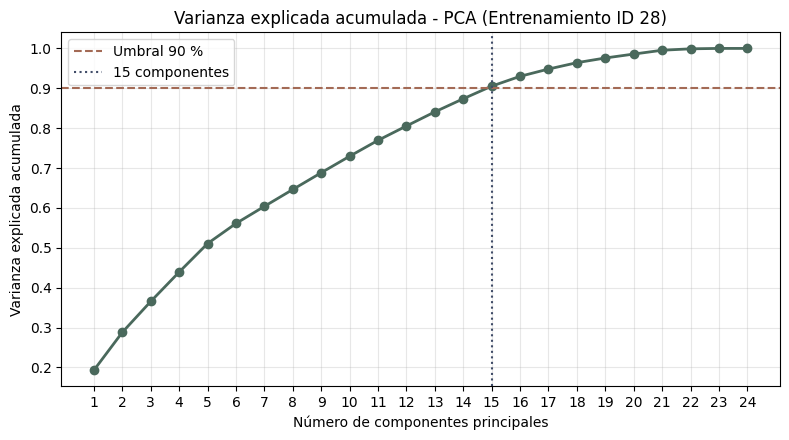

In [16]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from scipy.stats import ks_2samp

# 1. Preprocesar solo variables numéricas en entrenamiento para analizar PCA
prep_num_pca = make_pipeline(
    SimpleImputer(strategy='median'),
    StandardScaler(),
    PCA(svd_solver='full', random_state=semilla)
)
prep_num_pca.fit(X_train[columnas_numericas])

pca_obj = prep_num_pca.named_steps['pca']
varianza_acumulada = np.cumsum(pca_obj.explained_variance_ratio_)

# Número mínimo de componentes que explican >= 90% de la varianza
n_comp_90 = int(np.argmax(varianza_acumulada >= 0.90) + 1)

print(f"Variables numéricas iniciales: {len(columnas_numericas)}")
print(f"Componentes retenidas (>= 90% varianza): {n_comp_90}")
print(f"Varianza exacta explicada con {n_comp_90} componentes: {varianza_acumulada[n_comp_90 - 1]:.4f}")

# Gráfica de varianza explicada acumulada
plt.figure(figsize=(8, 4.5))
componentes_idx = np.arange(1, len(varianza_acumulada) + 1)
plt.plot(componentes_idx, varianza_acumulada, marker='o', color='#4a695c', linewidth=2)
plt.axhline(0.90, color='#a36a55', linestyle='--', label='Umbral 90 %')
plt.axvline(n_comp_90, color='#404c68', linestyle=':', label=f'{n_comp_90} componentes')
plt.title('Varianza explicada acumulada - PCA (Entrenamiento ID 28)')
plt.xlabel('Número de componentes principales')
plt.ylabel('Varianza explicada acumulada')
plt.xticks(componentes_idx)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## Actividades 2 y 3. Comparación controlada de modelos y costo empresarial

Para evaluar de manera objetiva si la reducción de dimensionalidad y los cambios en la regularización mejoran el desempeño predictivo, se ejecutan cuatro configuraciones controladas sobre la misma partición de validación (`X_valid`), manteniendo constante `class_weight='balanced'` y el umbral de decisión en `0.50`:

* **Experimento A (Referencia):** Variables numéricas originales (sin PCA) y regularización estándar ($C = 1.0$).
* **Experimento B (Efecto de PCA):** Variables numéricas reducidas al 90 % de varianza con PCA y regularización estándar ($C = 1.0$).
* **Experimento C (Mayor penalización):** PCA al 90 % de varianza con regularización L2 más estricta ($C = 0.1$) para restringir la magnitud de los coeficientes.
* **Experimento D (Menor penalización):** PCA al 90 % de varianza con regularización L2 más flexible ($C = 10.0$).

Para cada experimento se calculan métricas de clasificación (*Accuracy*, *Precision*, *Recall*, *F1-Score* y *Average Precision*) junto con el **costo operativo didáctico** ($\text{Costo} = 8 \times \text{FP} + 35 \times \text{FN}$), permitiendo contrastar el rendimiento estadístico frente al impacto financiero.

In [17]:
experimentos = [
    {'id': 'A', 'nombre': 'A. Referencia (Sin PCA, C=1.0)', 'usar_pca': False, 'C': 1.0},
    {'id': 'B', 'nombre': 'B. PCA 90% (C=1.0)',             'usar_pca': True,  'C': 1.0},
    {'id': 'C', 'nombre': 'C. PCA 90% + Mayor reg (C=0.1)', 'usar_pca': True,  'C': 0.1},
    {'id': 'D', 'nombre': 'D. PCA 90% + Menor reg (C=10.0)','usar_pca': True,  'C': 10.0},
]

resultados_s14 = []

for exp in experimentos:
    if exp['usar_pca']:
        pasos_num = make_pipeline(
            SimpleImputer(strategy='median'),
            StandardScaler(),
            PCA(n_components=0.90, svd_solver='full', random_state=semilla)
        )
    else:
        pasos_num = make_pipeline(
            SimpleImputer(strategy='median'),
            StandardScaler()
        )

    prep_exp = ColumnTransformer([
        ('numericas', pasos_num, columnas_numericas),
        ('categoricas', make_pipeline(SimpleImputer(strategy='most_frequent'),
                                     OneHotEncoder(handle_unknown='ignore')),
         columnas_categoricas)
    ])

    clf = make_pipeline(
        prep_exp,
        LogisticRegression(C=exp['C'], class_weight='balanced', max_iter=1000, random_state=semilla)
    )

    clf.fit(X_train, y_train)
    pred_exp = clf.predict(X_valid)
    proba_exp = clf.predict_proba(X_valid)[:, 1]

    tn, fp, fn, tp = confusion_matrix(y_valid, pred_exp).ravel()
    costo = int(8 * fp + 35 * fn)

    resultados_s14.append({
        'Experimento': exp['nombre'],
        'PCA': 'Sí (90%)' if exp['usar_pca'] else 'No',
        'C': exp['C'],
        'Accuracy': round(float(accuracy_score(y_valid, pred_exp)), 4),
        'Precision': round(float(precision_score(y_valid, pred_exp, zero_division=0)), 4),
        'Recall': round(float(recall_score(y_valid, pred_exp, zero_division=0)), 4),
        'F1': round(float(f1_score(y_valid, pred_exp, zero_division=0)), 4),
        'AP': round(float(average_precision_score(y_valid, proba_exp)), 4),
        'FP': int(fp),
        'FN': int(fn),
        'Costo_BRL': costo
    })

tabla_comparacion = pd.DataFrame(resultados_s14)
display(tabla_comparacion)

,Experimento,PCA,C,Accuracy,Precision,Recall,F1,AP,FP,FN,Costo_BRL
0,"A. Referencia (Sin PCA, C=1.0)",No,1.0,0.6644,0.1212,0.6338,0.2034,0.1387,1632,130,17606
1,B. PCA 90% (C=1.0),Sí (90%),1.0,0.6541,0.1112,0.5887,0.1871,0.1252,1670,146,18470
2,C. PCA 90% + Mayor reg (C=0.1),Sí (90%),0.1,0.6550,0.1132,0.6000,0.1904,0.1234,1669,142,18322
3,D. PCA 90% + Menor reg (C=10.0),Sí (90%),10.0,0.6535,0.1123,0.5972,0.1890,0.1246,1676,143,18413


## Actividad 4. Validación estadística entre particiones (Prueba Kolmogorov-Smirnov)

En esta etapa se aplica la **prueba no paramétrica de Kolmogorov-Smirnov (KS) de dos muestras** sobre la variable continua `valor_flete` para verificar si su distribución empírica es consistente entre los conjuntos de entrenamiento (`train`) y validación (`valid`).

Se evalúan las siguientes hipótesis bajo un nivel de significancia de $\alpha = 0.05$:
* **$H_0$ (Hipótesis nula):** La variable `valor_flete` proviene de la misma distribución en entrenamiento y validación.
* **$H_1$ (Hipótesis alternativa):** Las distribuciones de `valor_flete` difieren entre ambas particiones.

Se calcula el estadístico $D$ (máxima distancia vertical entre las funciones de distribución acumulada empírica) y el valor $p$ para comprobar la estabilidad de la partición aleatoria estratificada.

In [18]:
flete_train = train['valor_flete'].dropna()
flete_valid = valid['valor_flete'].dropna()

ks_res = ks_2samp(flete_train, flete_valid, alternative='two-sided')

print(f"n_train: {len(flete_train)} | n_valid: {len(flete_valid)}")
print(f"Mediana flete train: {flete_train.median():.2f} | Mediana flete valid: {flete_valid.median():.2f}")
print(f"Estadístico D: {ks_res.statistic:.5f}")
print(f"Valor p: {ks_res.pvalue:.5f}")
print("Decisión (alpha=0.05):", "Rechazar H0" if ks_res.pvalue < 0.05 else "No rechazar H0")

n_train: 24500 | n_valid: 5250
Mediana flete train: 17.19 | Mediana flete valid: 16.95
Estadístico D: 0.01822
Valor p: 0.11199
Decisión (alpha=0.05): No rechazar H0


## Registro de resultados y bitácora de experimentos (S14)

Finalmente, se consolidan los metadatos de reproducibilidad (ID de estudiante **28**, semilla **1028** y huella de la muestra), los parámetros obtenidos en la reducción de dimensionalidad con PCA, la tabla comparativa de los cuatro experimentos (métricas y costos en BRL) y el resultado del contraste estadístico KS. Toda esta información se exporta en el archivo `reports/S14_resultados_ID_28.json` como evidencia verificable para el repositorio.
```[cite: 23, 24]

In [19]:
import sys
import sklearn

# Identificar automáticamente el experimento de menor costo y el de mayor F1
mejor_costo_row = tabla_comparacion.loc[tabla_comparacion['Costo_BRL'].idxmin()]
mejor_f1_row = tabla_comparacion.loc[tabla_comparacion['F1'].idxmax()]
exp_a = tabla_comparacion.iloc[0]
exp_b = tabla_comparacion.iloc[1]

decision_ks = 'Rechazar H0' if ks_res.pvalue < 0.05 else 'No rechazar H0'
interpretacion_ks = (
    'existe evidencia estadística de diferencia entre las distribuciones de `valor_flete` en entrenamiento y validación'
    if ks_res.pvalue < 0.05 else
    'no se dispone de evidencia estadística suficiente para afirmar que las distribuciones de `valor_flete` difieran entre particiones (lo cual no demuestra equivalencia exacta)'
)

# 1. Guardar archivo JSON (Registro técnico de experimentos)
reporte_s14 = {
    'laboratorio': 'S14',
    'id_estudiante': identificador,
    'semilla': semilla,
    'timestamp_utc': pd.Timestamp.utcnow().isoformat(),
    'python': sys.version.split()[0],
    'pandas': pd.__version__,
    'numpy': np.__version__,
    'sklearn': sklearn.__version__,
    'n_muestra': len(muestra),
    'n_train': len(train),
    'n_valid': len(valid),
    'n_test': len(test),
    'huella_muestra': huella_muestra,
    'pca': {
        'variables_numericas_iniciales': len(columnas_numericas),
        'componentes_retenidas_90': n_comp_90,
        'varianza_explicada_acumulada': float(varianza_acumulada[n_comp_90 - 1])
    },
    'experimentos': resultados_s14,
    'mejor_por_costo': mejor_costo_row.to_dict(),
    'prueba_ks_valor_flete': {
        'estadistico_D': float(ks_res.statistic),
        'valor_p': float(ks_res.pvalue),
        'alpha': 0.05,
        'decision': decision_ks
    }
}

ruta_json = Path(f'reports/S14_resultados_ID_{identificador}.json')
ruta_json.parent.mkdir(parents=True, exist_ok=True)
ruta_json.write_text(json.dumps(reporte_s14, indent=2, ensure_ascii=False), encoding='utf-8')

# 2. Construir tabla Markdown manualmente (sin requerir librerías extra como tabulate)
encabezados = "| " + " | ".join(tabla_comparacion.columns) + " |"
separador = "| " + " | ".join(["---"] * len(tabla_comparacion.columns)) + " |"
filas_md = [
    "| " + " | ".join(str(val) for val in fila) + " |"
    for fila in tabla_comparacion.values
]
tabla_md = "\n".join([encabezados, separador] + filas_md)

# 3. Guardar archivo Markdown (Resumen ejecutivo del análisis)
resumen_md = f"""# Resumen Ejecutivo — Laboratorio 2 (Semana 14)
**Estudiante:** Sergio David Vargas Garzón
**ID Estudiante:** {identificador} | **Semilla:** {semilla} | **Huella de muestra:** `{huella_muestra}`

---

## 1. Reducción de Dimensionalidad (PCA)
* **Variables numéricas iniciales:** {len(columnas_numericas)}
* **Componentes principales retenidas ($\ge 90\%$ varianza):** {n_comp_90} componentes ({varianza_acumulada[n_comp_90 - 1]*100:.2f}% de varianza exacta explicada).
* **Análisis:** PCA comprime la colinealidad entre variables numéricas (como peso, volumen, precios y fletes) manteniendo el 90% de la dispersión geométrica. Sin embargo, maximizar varianza no garantiza conservar toda la señal discriminante de la clase minoritaria (`is_late`), pudiendo descartar información sutil contenida en direcciones de baja varianza.

---

## 2. Comparación de Experimentos y Costo Empresarial
Todos los modelos se evaluaron sobre la partición de validación (`n = {len(valid)}`) con `class_weight='balanced'` y umbral de `0.50`:

{tabla_md}

* **Efecto de PCA (B vs. A):** El modelo sin PCA obtuvo un F1 de **{exp_a['F1']}** y costo de **R$ {exp_a['Costo_BRL']:,}**, frente al modelo con PCA (C=1.0) con F1 de **{exp_b['F1']}** y costo de **R$ {exp_b['Costo_BRL']:,}**.
* **Elección empresarial:** Se selecciona el experimento **{mejor_costo_row['Experimento']}**, ya que minimiza el impacto financiero en validación con un costo total de **R$ {mejor_costo_row['Costo_BRL']:,}** (FP: {mejor_costo_row['FP']}, FN: {mejor_costo_row['FN']}), priorizando la reducción de falsos negativos (R$ 35 c/u) frente a falsas alarmas (R$ 8 c/u).

---

## 3. Validación Estadística (Prueba Kolmogorov-Smirnov)
* **Variable evaluada:** `valor_flete` entre entrenamiento (`n = {len(flete_train)}`) y validación (`n = {len(flete_valid)}`).
* **Hipótesis:** $H_0$: ambas muestras provienen de la misma distribución; $H_1$: las distribuciones difieren ($\alpha = 0.05$).
* **Resultados:** Estadístico $D = {ks_res.statistic:.5f}$, valor $p = {ks_res.pvalue:.5f}$ $\rightarrow$ **{decision_ks}**.
* **Interpretación y limitación:** Con un nivel de significancia del 5%, {interpretacion_ks}. Como limitación metodológica, la prueba KS asume distribuciones continuas sin empates (mientras que los montos monetarios presentan valores repetidos por redondeo) y evalúa únicamente la similitud marginal de una variable, sin medir la capacidad predictiva de los clasificadores.
"""

ruta_md = Path(f'reports/S14_resumen_ID_{identificador}.md')
ruta_md.write_text(resumen_md, encoding='utf-8')

print("Archivos generados exitosamente:")
print(" -", ruta_json)
print(" -", ruta_md)

# Descarga automática en Google Colab
try:
    from google.colab import files
    files.download(str(ruta_json))
    files.download(str(ruta_md))
except Exception:
    print("Descargue manualmente los archivos desde el panel izquierdo de archivos en Colab (carpeta reports/).")

Archivos generados exitosamente:
 - reports/S14_resultados_ID_28.json
 - reports/S14_resumen_ID_28.md


<>:90: SyntaxWarning: invalid escape sequence '\g'
<>:90: SyntaxWarning: invalid escape sequence '\g'
/tmp/ipykernel_1409/3016596954.py:90: SyntaxWarning: invalid escape sequence '\g'
  


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Conclusiones de la Semana 14 (ID 28)

### 1. Reducción de Dimensionalidad mediante PCA
* **Resultados obtenidos:** A partir de las **24 variables numéricas** originales ajustadas exclusivamente sobre entrenamiento (`n = 24,500`), el Análisis de Componentes Principales requirió **15 componentes** para superar el umbral del 90 %, explicando exactamente el **90.54 %** de la varianza acumulada (`0.9054`).
* **Utilidad para el problema:** PCA permite condensar en 15 ejes ortogonales la colinealidad existente entre grupos de variables correlacionadas del pedido (como peso total/máximo, volumen, precios y costos de flete), reduciendo redundancia lineal. Sin embargo, dado que PCA es una técnica no supervisada que prioriza direcciones de máxima dispersión geométrica y no de separabilidad entre clases, descartar el ~9.46 % restante de varianza puede eliminar señales sutiles relevantes para predecir entregas tardías (`is_late`, clase minoritaria con 6.77 %).


### 2. Contraste entre el Modelo sin PCA y los Modelos con PCA
Al evaluar las cuatro configuraciones sobre el conjunto de validación (`n = 5,250`, manteniendo `class_weight='balanced'` y umbral `0.50`), se observó el siguiente comportamiento:

| Experimento | PCA | Regularización ($C$) | Accuracy | Precision | Recall | F1 | AP | FP | FN | Costo (BRL) |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| **A. Referencia** | No | 1.0 | **0.6644** | **0.1212** | **0.6338** | **0.2034** | **0.1387** | **1,632** | **130** | **R 17,606** |
| **B. PCA 90%** | Sí (90%) | 1.0 | 0.6541 | 0.1112 | 0.5887 | 0.1871 | 0.1252 | 1,670 | 146 | R 18,470 |
| **C. PCA + Mayor reg.** | Sí (90%) | 0.1 | 0.6550 | 0.1132 | 0.6000 | 0.1904 | 0.1234 | 1,669 | 142 | R 18,322 |
| **D. PCA + Menor reg.** | Sí (90%) | 10.0 | 0.6535 | 0.1123 | 0.5972 | 0.1890 | 0.1246 | 1,676 | 143 | R 18,413 |

* **Efecto de aplicar PCA (B vs. A):** Comprimir las variables numéricas degradó todas las métricas de clasificación: el *Recall* cayó de `0.6338` a `0.5887` (-4.51 puntos porcentuales), el *F1-Score* bajó de `0.2034` a `0.1871` y el *Average Precision (AP)* descendió de `0.1387` a `0.1252`. Esto confirma que las combinaciones lineales descartadas por PCA contenían señal discriminante útil para la regresión logística.
* **Efecto de la regularización (C y D vs. B):** Endurecer la penalización L2 ($C = 0.1$, Experimento C) recuperó ligeramente la sensibilidad (*Recall* de `0.6000` y *F1* de `0.1904`) respecto a $C = 1.0$, mientras que relajarla ($C = 10.0$, Experimento D) incrementó los falsos positivos (`1,676`) sin mejorar la capacidad predictiva. No obstante, ninguno de los modelos con PCA superó al modelo original sin PCA.


### 3. Decisión Basada en Costo Operativo
* **Modelo seleccionado:** Se elige el **Experimento A (Sin PCA, $C = 1.0$)** como mejor alternativa operativa.
* **Justificación financiera:** Bajo la estructura de costos del negocio (**R 8**  por falso positivo frente a  **R 35** por falso negativo una asimetría de 4.375 a 1), el Experimento A logra simultáneamente la menor cantidad de falsas alarmas (**1,632 FP**) y la menor cantidad de retrasos no detectados (**130 FN**), generando el **menor costo total en validación con R 17,606** (un ahorro de **R 864** frente al Experimento B y de **R 716** frente al Experimento C). Para la operación logística de Olist, no conviene guiar la decisión únicamente por *Accuracy* global, sino por la combinación de mayor *Recall* y menor costo financiero esperado.

### 4. Validación Estadística con Prueba Kolmogorov-Smirnov
* **Planteamiento de hipótesis ($\alpha = 0.05$):**
  * **$H_0$:** La variable `valor_flete` proviene de la misma distribución continua en entrenamiento (`n = 24,500`) y validación (`n = 5,250`).
  * **$H_1$:** Las distribuciones de `valor_flete` difieren entre ambas particiones.
* **Resultados y decisión:** Las medianas son muy cercanas (**R 17.19** en entrenamiento vs. **R 16.95** en validación), obteniendo un estadístico **D = 0.01822** y un **valor p = 0.111990**. Dado que $p = 0.11199 > 0.05$, **no se rechaza $H_0$**. Esto indica que no existe evidencia estadística de sesgo o desplazamiento (*drift*) en el costo de envío entre las particiones generadas con la semilla `1028`.
* **Limitación metodológica:** No rechazar $H_0$ no demuestra matemáticamente que ambas distribuciones sean idénticas. Además, la prueba KS está formulada teóricamente para distribuciones estrictamente continuas sin empates (*ties*), mientras que `valor_flete` es una variable monetaria redondeada a dos decimales con múltiples valores repetidos (lo que hace conservador el cálculo del valor $p$), y evalúa únicamente una variable de forma univariada sin medir la capacidad predictiva real del modelo.

